<a href="https://colab.research.google.com/github/omarelmalak/csc490-group2/blob/main/OWL_Match_Labeler_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Logo labeler for one match (OWLv2, Colab)

Finds sponsor logos (Riyadh Air, Hyundai, Nike, ...) in the frames of **one match** and writes YOLO labels,
using a few example boxes you give it from that same match. All brands are detected in one pass.

### What you upload (one folder in your Google Drive)
```
my_match/
  frames/          frames from this one match (.jpg / .png)
  examples.txt     your example boxes (format below)
```

### `examples.txt`
One example per line: **brand, frame, box** (pixel corners `x1,y1,x2,y2` in that frame). Lines starting with `#` are ignored.
```
riyadh_air  frame_00000.jpg  130,216,166,262
hyundai     frame_00870.jpg  456,230,492,252
nike        frame_00754.jpg  404,186,426,203
negative    frame_00199.jpg  527,28,543,44      # things that must NOT be labeled (crests, league badge, numbers...)
```
**Tips for good examples** (these matter more than anything else):
- **3-10 per brand**, covering each kit (home / away / keeper), different angles and some blur.
- **Box only the logo, tightly.** Background inside the box becomes part of what it searches for.
- Add `negative` lines for lookalikes it gets wrong (club crests, kit-maker logos, the league badge, shirt numbers).
- Each brand's examples automatically count as negatives for the other brands.

### Run
1. **Runtime → Change runtime type → T4 GPU**
2. Set `MATCH_DIR` (and `CLASSES` if your match has a new sponsor) in step 1, then run the cells top to bottom.
3. Check the example previews (step 5) and the boxes (step 8) - adjust cutoffs in step 9 if needed.

Results are written into `MATCH_DIR/owl_output/`: `labels/` (YOLO), `annotated/` (frames with boxes),
`candidates/` (every candidate with its score, for changing cutoffs), `summary.csv`, and `yolo_dataset/` from step 10.
If Colab disconnects, run the cells again - step 7 continues where it stopped.

In [1]:
# 1. Settings - edit these
MATCH_DIR = "/content/drive/MyDrive/my_match"    # folder with frames/ and examples.txt

# Shared brand list: the position is the YOLO class number (riyadh_air = 0, hyundai = 1, ...).
# Keep it the SAME for everyone so labels from different matches can be combined.
# New sponsor? Add it at the END only - never reorder or remove.
CLASSES = ["riyadh_air", "hyundai", "nike", "adidas"]

DEFAULT_CUTOFF = 0.93   # a box needs at least this score (0.93 checked on Atletico vs Real: few mistakes)
CUTOFFS = {}            # per-brand overrides, e.g. {"riyadh_air": 0.92}
TILES = 2               # 2 = also scan 4 enlarged tiles per frame (finds small logos, ~5x the work); 1 = whole frame only
ONLY_FRAMES = None      # quick test on a few frames, e.g. ["frame_00870", "frame_00102"]; None = all frames

In [2]:
# 2. GPU check (should print a Tesla T4; "no GPU" means it will be very slow)
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU - Runtime > Change runtime type > T4 GPU")

GPU: Tesla T4


In [3]:
# 3. Connect Google Drive and find the match files
import os, shutil
from pathlib import Path

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:          # running in Jupyter on your own computer
    IN_COLAB = False

MATCH = Path(MATCH_DIR)
FRAMES_SRC = MATCH / "frames"
EXAMPLES_TXT = MATCH / "examples.txt"
OUT = MATCH / "owl_output"
assert FRAMES_SRC.is_dir(), f"no frames/ folder in {MATCH}"
assert EXAMPLES_TXT.is_file(), f"no examples.txt in {MATCH}"

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
# reading from Drive is slow, so work on a local copy of the frames in Colab
FRAMES = Path("/content/frames_local") if IN_COLAB else FRAMES_SRC
if IN_COLAB:
    FRAMES.mkdir(exist_ok=True)
    for p in FRAMES_SRC.iterdir():
        if p.suffix.lower() in IMAGE_EXTS and not (FRAMES / p.name).exists():
            shutil.copy(p, FRAMES / p.name)
FRAME_FILES = {p.stem: p for p in sorted(FRAMES.iterdir()) if p.suffix.lower() in IMAGE_EXTS}
for sub in ("labels", "annotated", "candidates"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)
print(f"{len(FRAME_FILES)} frames | examples: {EXAMPLES_TXT} | output: {OUT}")

Mounted at /content/drive
385 frames | examples: /content/drive/MyDrive/my_match/examples.txt | output: /content/drive/MyDrive/my_match/owl_output


In [4]:
# 4. Make sure transformers has OWLv2 (only installs if missing)
try:
    from transformers import Owlv2ForObjectDetection  # noqa: F401
    print("transformers OK")
except ImportError:
    !pip -q install -U transformers
    print("installed transformers - if the next cells fail, use Runtime > Restart session and run from step 1")

transformers OK


examples per brand: {'riyadh_air': 5, 'hyundai': 9, 'nike': 5, 'negative': 17}
brands with no examples (will not be detected): ['adidas']

riyadh_air: 5 example(s)


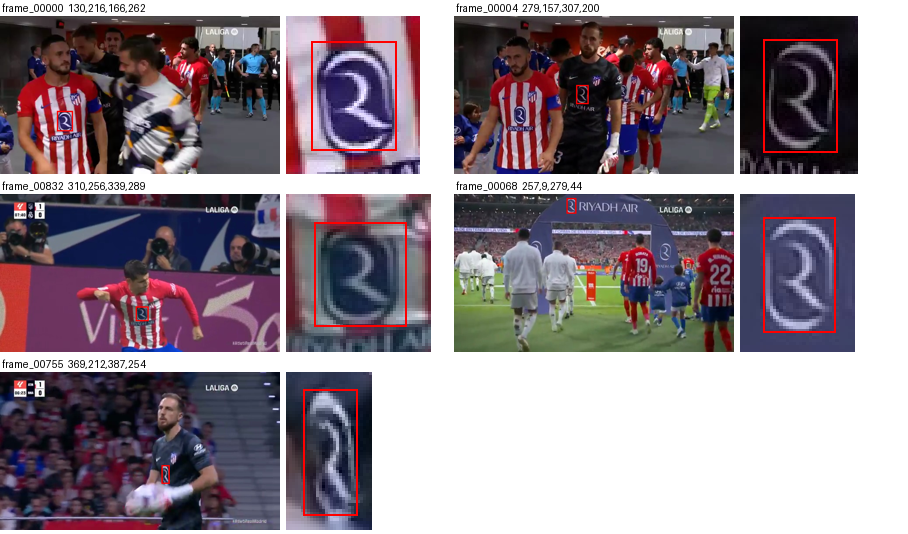


hyundai: 9 example(s)


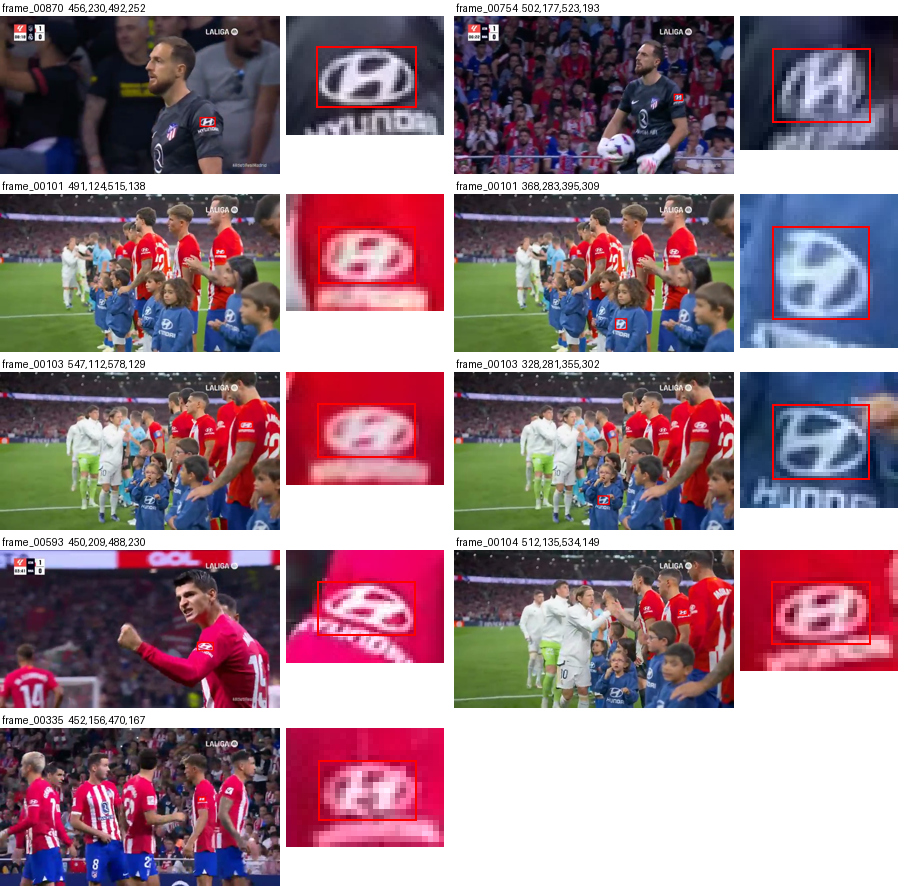


nike: 5 example(s)


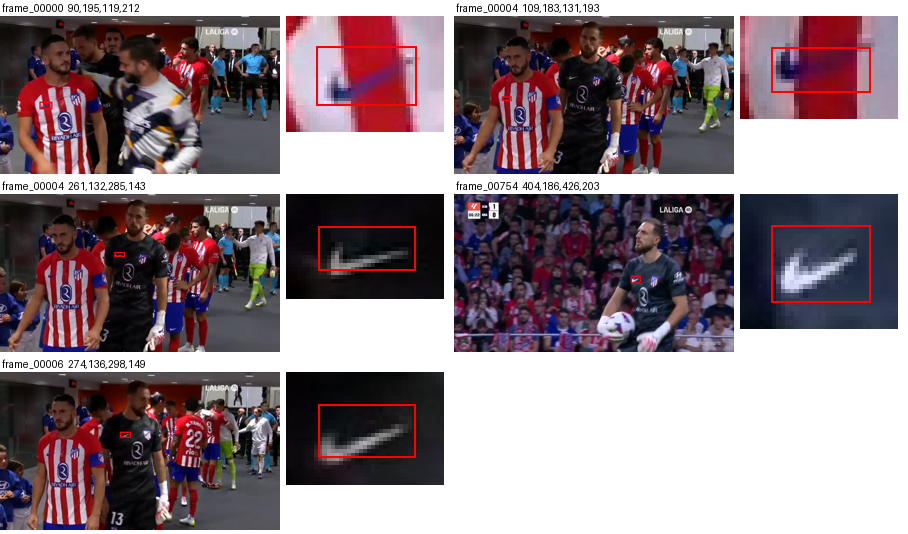


negative: 17 example(s)


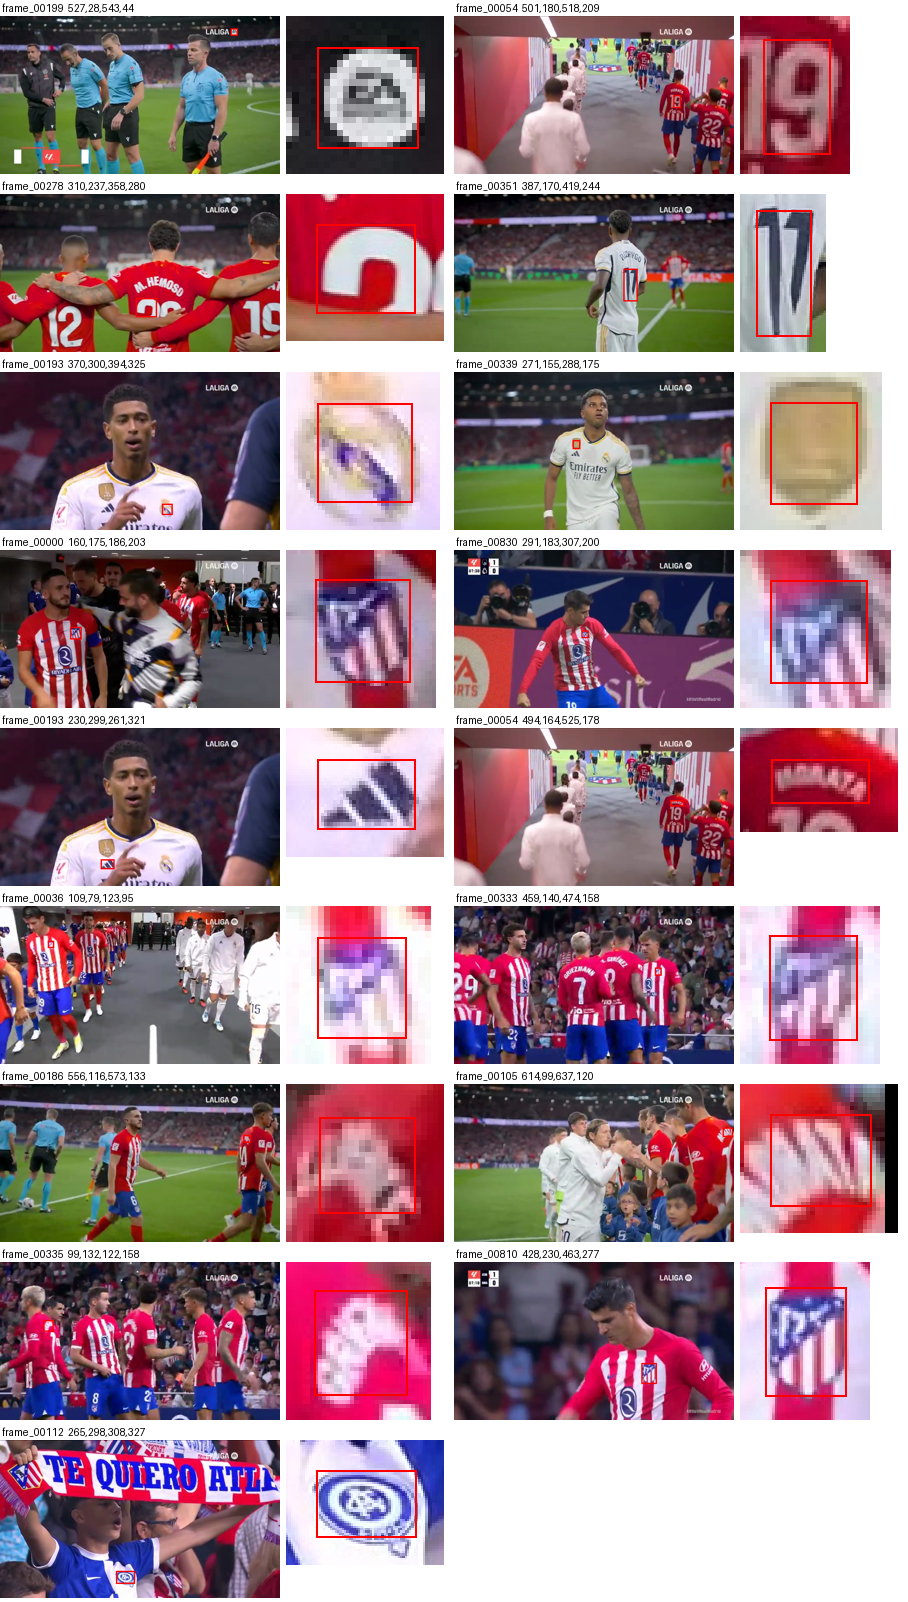

In [5]:
#@title 5. Check examples.txt and preview every example (red box = what it learns from)
from PIL import Image, ImageDraw
from IPython.display import display

def read_examples():
    examples, errors, warnings = [], [], []
    for n, raw in enumerate(open(EXAMPLES_TXT, encoding="utf-8"), 1):
        line = raw.split("#", 1)[0].strip()
        if not line:
            continue
        parts = line.split()
        if len(parts) != 3:
            errors.append(f"line {n}: expected 'brand frame x1,y1,x2,y2', got: {raw.strip()}"); continue
        brand, frame, box = parts
        if brand != "negative" and brand not in CLASSES:
            errors.append(f"line {n}: brand '{brand}' is not in CLASSES (add it at the END of CLASSES in step 1) or use 'negative'"); continue
        stem = Path(frame).stem
        if stem not in FRAME_FILES:
            errors.append(f"line {n}: frame '{frame}' not found in frames/"); continue
        try:
            x1, y1, x2, y2 = (float(v) for v in box.split(","))
        except ValueError:
            errors.append(f"line {n}: box must be x1,y1,x2,y2 numbers, got '{box}'"); continue
        W, H = Image.open(FRAME_FILES[stem]).size
        if not (0 <= x1 < x2 <= W and 0 <= y1 < y2 <= H):
            errors.append(f"line {n}: box {box} is not inside the {W}x{H} frame (need x1<x2, y1<y2)"); continue
        if min(x2 - x1, y2 - y1) < 8:
            warnings.append(f"line {n}: box {box} is very small ({x2-x1:.0f}x{y2-y1:.0f} px) - fine if the logo really is that small")
        examples.append((brand, stem, (x1, y1, x2, y2)))
    return examples, errors, warnings

def preview_examples(examples):
    for brand in [b for b in CLASSES if any(e[0] == b for e in examples)] + ["negative"]:
        rows = [e for e in examples if e[0] == brand]
        if not rows:
            continue
        TW, TH, Z = 280, 158, 158
        sheet = Image.new("RGB", (2 * (TW + Z + 16), ((len(rows) + 1) // 2) * (TH + 20)), "white"); d = ImageDraw.Draw(sheet)
        for i, (_, stem, (x1, y1, x2, y2)) in enumerate(rows):
            im = Image.open(FRAME_FILES[stem]).convert("RGB")
            th = im.copy(); ImageDraw.Draw(th).rectangle([x1, y1, x2, y2], outline=(255, 0, 0), width=max(2, im.width // 200)); th.thumbnail((TW, TH))
            m = max(4, (x2 - x1) * 0.3); cx0, cy0 = int(x1 - m), int(y1 - m)
            z = im.crop((cx0, cy0, int(x2 + m), int(y2 + m)))
            s = min(Z / z.width, Z / z.height); z = z.resize((max(1, int(z.width * s)), max(1, int(z.height * s))), Image.NEAREST)
            ImageDraw.Draw(z).rectangle([(x1 - cx0) * s, (y1 - cy0) * s, (x2 - cx0) * s, (y2 - cy0) * s], outline=(255, 0, 0), width=2)
            x, y = (i % 2) * (TW + Z + 16), (i // 2) * (TH + 20)
            d.text((x + 2, y + 2), f"{stem}  {int(x1)},{int(y1)},{int(x2)},{int(y2)}", fill=(0, 0, 0))
            sheet.paste(th, (x, y + 16)); sheet.paste(z, (x + TW + 6, y + 16))
        print(f"\n{brand}: {len(rows)} example(s)")
        display(sheet)

EXAMPLES, errs, warns = read_examples()
for w in warns: print("warning:", w)
if errs:
    print("\n".join("ERROR: " + e for e in errs))
    raise SystemExit("Fix examples.txt (see errors above), re-upload it, and run this cell again.")
counts = {b: sum(e[0] == b for e in EXAMPLES) for b in CLASSES + ["negative"]}
print("examples per brand:", {b: n for b, n in counts.items() if n})
print("brands with no examples (will not be detected):", [b for b in CLASSES if not counts[b]])
preview_examples(EXAMPLES)

In [6]:
#@title 6. Load the OWLv2 model and learn the examples
import time, csv
import torchvision
import torch.nn.functional as F
from transformers import Owlv2Processor, Owlv2ForObjectDetection

Image.MAX_IMAGE_PIXELS = None
MAX_SIDE = 1600       # bigger frames are shrunk to this (labels are fractions of the size, so they stay valid)
OVERLAP = 0.25        # tile overlap
CONTAIN = 0.6         # a box >60% inside a bigger box of the same brand is a logo part -> dropped
SAVE_FLOOR = 0.80     # candidates at or above this are saved, so cutoffs can be lowered to here later
MARGIN = 0.0          # a box must beat its best negative match by this much
DEV = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

MODEL_NAME = "google/owlv2-base-patch16-ensemble"
proc = Owlv2Processor.from_pretrained(MODEL_NAME)
model = Owlv2ForObjectDetection.from_pretrained(MODEL_NAME).to(DEV).eval()
print("model loaded on", DEV)

def load(path):
    img = Image.open(path).convert("RGB")
    if max(img.size) > MAX_SIDE:
        img.thumbnail((MAX_SIDE, MAX_SIDE))
    return img

@torch.no_grad()
def embed_batch(imgs):
    # OWL proposals for a batch of images: unit-length embeddings, cxcywh boxes (0-1 of the padded square)
    pv = proc(images=imgs, return_tensors="pt")["pixel_values"].to(DEV)
    fmap = model.image_embedder(pixel_values=pv)[0]
    b, h, w, d = fmap.shape
    feats = fmap.reshape(b, h * w, d)
    _, cls = model.class_predictor(feats)
    boxes = model.box_predictor(feats, fmap)
    return F.normalize(cls, dim=-1), boxes.cpu()

def to_pixels(boxes, w, h):
    b = torchvision.ops.box_convert(boxes, "cxcywh", "xyxy") * max(w, h)
    b[:, 0::2] = b[:, 0::2].clamp(0, w); b[:, 1::2] = b[:, 1::2].clamp(0, h)
    return b

def tile_size(W, H):
    return W / (TILES - (TILES - 1) * OVERLAP), H / (TILES - (TILES - 1) * OVERLAP)

def tile_windows(W, H):
    # overlapping TILES x TILES windows that together cover the whole frame
    if TILES <= 1:
        return []
    tw, th = tile_size(W, H); sx, sy = tw * (1 - OVERLAP), th * (1 - OVERLAP)
    return [(round(i * sx), round(j * sy), min(W, round(i * sx + tw)), min(H, round(j * sy + th)))
            for j in range(TILES) for i in range(TILES)]

def proposals(img):
    # all OWL boxes from the whole frame + tiles (one GPU batch), in frame pixels, with embeddings
    W, H = img.size
    wins = [None] + tile_windows(W, H)
    crops = [img if w is None else img.crop(w) for w in wins]
    cls, boxes = embed_batch(crops)
    all_e, all_b = [], []
    for k, (win, crop) in enumerate(zip(wins, crops)):
        cw, ch = crop.size
        b, e = to_pixels(boxes[k], cw, ch), cls[k]
        if win is not None:  # drop boxes cut by an inner tile edge (a neighbour tile / the full frame sees them whole)
            x0, y0, x1, y1 = win; E = 2
            cut = ((b[:, 0] <= E) & (x0 > 0)) | ((b[:, 2] >= cw - E) & (x1 < W)) | \
                  ((b[:, 1] <= E) & (y0 > 0)) | ((b[:, 3] >= ch - E) & (y1 < H))
            b, e = b[~cut] + torch.tensor([x0, y0, x0, y0], dtype=b.dtype), e[~cut.to(e.device)]
        all_b.append(b); all_e.append(e)
    return torch.cat(all_e), torch.cat(all_b)

def best_overlap_embedding(img, target):
    cls, boxes = embed_batch([img])
    iou = torchvision.ops.box_iou(to_pixels(boxes[0], *img.size), target)[:, 0]
    i = int(iou.argmax())
    return cls[0][i], float(iou[i])

def example_embeddings(stem, box):
    # an example is learned from the FULL frame at its real size (+ a tile-sized window, matching the tile scale)
    path = FRAME_FILES[stem]
    with Image.open(path) as orig:
        scale = load(path).width / orig.width
    img = load(path)
    target = torch.tensor([[v * scale for v in box]])
    embs, overlaps = [], []
    e, ov = best_overlap_embedding(img, target); embs.append(e); overlaps.append(ov)
    if TILES > 1:
        W, H = img.size; tw, th = tile_size(W, H)
        cx, cy = float(target[0, 0] + target[0, 2]) / 2, float(target[0, 1] + target[0, 3]) / 2
        x0 = round(min(max(cx - tw / 2, 0), W - tw)); y0 = round(min(max(cy - th / 2, 0), H - th))
        win = img.crop((x0, y0, round(x0 + tw), round(y0 + th)))
        e, ov = best_overlap_embedding(win, target - torch.tensor([[x0, y0, x0, y0]]))
        embs.append(e); overlaps.append(ov)
    return embs, min(overlaps)

t0 = time.time()
BRAND_EMB, neg_list = {}, []
for brand, stem, box in EXAMPLES:
    embs, ov = example_embeddings(stem, box)
    if ov < 0.3:
        print(f"warning: {brand} example in {stem} {box}: OWL found no box matching it well (overlap {ov:.2f}) - check the box")
    (neg_list if brand == "negative" else BRAND_EMB.setdefault(brand, [])).extend(embs)
BRAND_EMB = {b: torch.stack(v) for b, v in BRAND_EMB.items()}
NEG_EMB = torch.stack(neg_list) if neg_list else None
BRAND_NAMES = list(BRAND_EMB)
print(f"learned {len(EXAMPLES)} examples in {time.time() - t0:.0f}s - detecting: {BRAND_NAMES}")

preprocessor_config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/67.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  620MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

model loaded on cuda
learned 36 examples in 28s - detecting: ['riyadh_air', 'hyundai', 'nike']


In [ ]:
#@title 7. Detect logos in all frames (continues where it stopped if re-run)
PALETTE = [(0, 255, 0), (255, 64, 64), (64, 160, 255), (255, 200, 0), (255, 0, 255), (0, 255, 255), (255, 128, 0), (160, 96, 255)]

def score_frame(img):
    # every box goes to the brand it matches best; kept if it beats all negatives
    e, b = proposals(img)
    sims = torch.stack([(e @ BRAND_EMB[n].T).max(dim=1).values for n in BRAND_NAMES], dim=1).cpu()
    best, idx = sims.max(dim=1)
    neg = (e @ NEG_EMB.T).max(dim=1).values.cpu() if NEG_EMB is not None else torch.full_like(best, -1.0)
    wh = b[:, 2:] - b[:, :2]
    ok = (wh[:, 0] > 6) & (wh[:, 1] > 6) & (best > neg + MARGIN) & (best >= SAVE_FLOOR)
    b, best, idx = b[ok], best[ok], idx[ok]
    keep = torchvision.ops.nms(b, best, 0.3)
    return [(BRAND_NAMES[int(idx[i])], float(best[i]), *[float(v) for v in b[i]]) for i in keep]

def cutoff(brand):
    return CUTOFFS.get(brand, DEFAULT_CUTOFF)

def kept_boxes(cands):
    # apply per-brand cutoffs, then drop logo parts (box mostly inside a bigger box of the same brand)
    kept = []
    for brand in {c[0] for c in cands}:
        rows = sorted((c for c in cands if c[0] == brand and c[1] >= cutoff(brand)),
                      key=lambda c: (c[4] - c[2]) * (c[5] - c[3]), reverse=True)
        mine = []
        for c in rows:
            area = (c[4] - c[2]) * (c[5] - c[3])
            if not any(max(0, min(c[4], k[4]) - max(c[2], k[2])) * max(0, min(c[5], k[5]) - max(c[3], k[3])) > CONTAIN * area for k in mine):
                mine.append(c)
        kept += mine
    return sorted(kept, key=lambda c: -c[1])

def read_candidates(stem):
    f = OUT / "candidates" / f"{stem}.txt"
    return [(p[0], *map(float, p[1:])) for p in (l.split() for l in f.read_text().splitlines()) if p] if f.exists() else []

def write_frame(stem, img, cands, annotate=True):
    W, H = img.size
    boxes = kept_boxes(cands)
    lines = [f"{CLASSES.index(br)} {(x1+x2)/2/W:.6f} {(y1+y2)/2/H:.6f} {(x2-x1)/W:.6f} {(y2-y1)/H:.6f}\n" for br, sc, x1, y1, x2, y2 in boxes]
    (OUT / "labels" / f"{stem}.txt").write_text("".join(lines))
    if annotate:
        im = img.copy(); d = ImageDraw.Draw(im); lw = max(2, max(W, H) // 300)
        for br, sc, x1, y1, x2, y2 in boxes:
            col = PALETTE[CLASSES.index(br) % len(PALETTE)]
            d.rectangle([x1, y1, x2, y2], outline=col, width=lw); d.text((x1 + 2, max(0, y1 - 12)), f"{br} {sc:.2f}", fill=col)
        im.save(OUT / "annotated" / f"{stem}.jpg", quality=90)
    return boxes

def run(resume=True):
    stems = [s for s in FRAME_FILES if not ONLY_FRAMES or s in {Path(f).stem for f in ONLY_FRAMES}]
    todo = [s for s in stems if not (resume and (OUT / "candidates" / f"{s}.txt").exists())]
    print(f"{len(stems)} frames, {len(stems) - len(todo)} already done, {len(todo)} to go")
    t0 = time.time()
    for i, stem in enumerate(todo, 1):
        img = load(FRAME_FILES[stem])
        cands = score_frame(img)
        boxes = write_frame(stem, img, cands)
        # candidates are written last: a frame counts as done only when everything for it is saved
        (OUT / "candidates" / f"{stem}.txt").write_text("".join(f"{c[0]} {c[1]:.4f} {c[2]:.1f} {c[3]:.1f} {c[4]:.1f} {c[5]:.1f}\n" for c in cands))
        if i == 1 or i % 25 == 0 or i == len(todo):
            el = time.time() - t0
            print(f"{i}/{len(todo)} frames  {el:.0f}s  (~{el / i * (len(todo) - i) / 60:.1f} min left)  last: {stem} -> "
                  + (", ".join(f"{b[0]} {b[1]:.2f}" for b in boxes) or "no logos"))
    summary()

def summary(save=True):
    rows = []
    done = [s for s in FRAME_FILES if (OUT / "candidates" / f"{s}.txt").exists()]
    for k, brand in enumerate(CLASSES):
        frames = boxes = 0; area = 0.0
        for s in done:
            mine = [l.split() for l in (OUT / "labels" / f"{s}.txt").read_text().splitlines() if l.split() and int(l.split()[0]) == k]
            frames += bool(mine); boxes += len(mine); area += sum(float(m[3]) * float(m[4]) for m in mine)
        rows.append({"class_id": k, "brand": brand, "cutoff": cutoff(brand), "frames_with_logo": frames,
                     "boxes": boxes, "avg_box_area_pct": round(100 * area / boxes, 3) if boxes else 0})
    print(f"\n{len(done)} frames labeled:")
    for r in rows:
        print(f"  {r['class_id']} {r['brand']:<12} cutoff {r['cutoff']:.2f}   frames {r['frames_with_logo']:>4}   boxes {r['boxes']:>4}   avg box {r['avg_box_area_pct']}% of frame")
    if save:
        with open(OUT / "summary.csv", "w", newline="") as f:
            w = csv.DictWriter(f, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)

run()

385 frames, 0 already done, 385 to go
1/385 frames  3s  (~16.8 min left)  last: frame_00000 -> nike 1.00, riyadh_air 1.00
25/385 frames  57s  (~13.8 min left)  last: frame_00024 -> no logos
50/385 frames  119s  (~13.3 min left)  last: frame_00049 -> no logos
75/385 frames  177s  (~12.2 min left)  last: frame_00074 -> no logos
100/385 frames  235s  (~11.2 min left)  last: frame_00099 -> hyundai 0.97
125/385 frames  293s  (~10.2 min left)  last: frame_00124 -> hyundai 0.94


In [ ]:
#@title 8. Check the boxes - every box zoomed in, sorted by score (lowest scores are the ones to doubt)
def show_boxes(brand=None, max_boxes=96, lowest_first=False):
    items = []
    for stem in FRAME_FILES:
        for c in kept_boxes(read_candidates(stem)):
            if brand is None or c[0] == brand:
                items.append((c[1], c[0], stem, *c[2:]))
    items.sort(reverse=not lowest_first)
    print(f"{len(items)} boxes" + (f" for {brand}" if brand else "") + (f" (showing {max_boxes})" if len(items) > max_boxes else ""))
    items = items[:max_boxes]
    if not items:
        return
    Z, COLS = 150, 8
    sheet = Image.new("RGB", (COLS * Z, ((len(items) + COLS - 1) // COLS) * (Z + 26)), "white"); d = ImageDraw.Draw(sheet)
    for i, (sc, br, stem, x1, y1, x2, y2) in enumerate(items):
        im = load(FRAME_FILES[stem]); m = max(x2 - x1, y2 - y1) * 1.2
        z = im.crop((int(x1 - m), int(y1 - m), int(x2 + m), int(y2 + m)))
        ImageDraw.Draw(z).rectangle([x1 - int(x1 - m), y1 - int(y1 - m), x2 - int(x1 - m), y2 - int(y1 - m)],
                                    outline=PALETTE[CLASSES.index(br) % len(PALETTE)], width=2)
        x, y = (i % COLS) * Z, (i // COLS) * (Z + 26)
        sheet.paste(z.resize((Z, Z)), (x, y + 26))
        d.text((x + 2, y + 1), f"{br} {sc:.3f}", fill=(0, 0, 0)); d.text((x + 2, y + 13), stem, fill=(90, 90, 90))
    display(sheet)

for b in BRAND_NAMES:
    show_boxes(b)

In [ ]:
# 9. Change a brand's cutoff (takes seconds - no model run). Lower = more logos but more mistakes.
#    Candidates were saved down to 0.80, so a cutoff can't go below that without re-running step 7 with resume=False.
def set_cutoff(brand, value, annotate=True):
    CUTOFFS[brand] = value
    for stem in FRAME_FILES:
        if (OUT / "candidates" / f"{stem}.txt").exists():
            write_frame(stem, load(FRAME_FILES[stem]), read_candidates(stem), annotate=annotate)
    summary()
    show_boxes(brand, lowest_first=True, max_boxes=48)

# set_cutoff("riyadh_air", 0.92)

In [ ]:
# 10. Export a YOLO dataset (frames that have at least one logo + their labels + data.yaml)
def export_yolo(include_empty=False):
    ds = OUT / "yolo_dataset"
    (ds / "images").mkdir(parents=True, exist_ok=True); (ds / "labels").mkdir(parents=True, exist_ok=True)
    n = 0
    for stem, path in FRAME_FILES.items():
        lab = OUT / "labels" / f"{stem}.txt"
        if lab.exists() and (include_empty or lab.stat().st_size > 0):
            shutil.copy(path, ds / "images" / path.name); shutil.copy(lab, ds / "labels" / lab.name); n += 1
    names = "\n".join(f"  {i}: {c}" for i, c in enumerate(CLASSES))
    (ds / "data.yaml").write_text(f"path: {ds}\ntrain: images\nval: images   # split by time before training\nnames:\n{names}\n")
    summary()
    print(f"\nexported {n} frames -> {ds}")

export_yolo()

### Notes
- **Changed `examples.txt` or `TILES`?** Re-run steps 5-6, then run step 7 as `run(resume=False)` so every frame is redone with the new examples.
- **Bad boxes on one kind of thing** (a crest, the league badge, a sponsor that isn't in `CLASSES`)? Add a few `negative` lines for it and re-run as above.
- **Missing logos?** Add more examples of that brand from frames where it was missed (different kit, angle, blur), or lower its cutoff in step 9.
- Before training, split train/val **by time** (e.g. first 80% of the match / last 20%), not randomly - neighbouring frames are near-duplicates.